<div style="text-align:center;background:#123047;color:white;padding:28px;border-radius:14px">
<h1 style="margin:0">HOUSEHOLD ENERGY EDA</h1>
<p style="font-size:17px;margin:10px 0 0">Exploratory Data Analysis · Consumption Patterns · Practical Findings</p>
</div>

**Project objective**  
Turn daily household electricity records into an understandable picture of usage, household differences, temperature relationships, peak-hour demand, and data quality.

**Dataset:** `household_energy_consumption(1).csv`  
**Approach:** inspect → validate → derive features → explore patterns → summarize findings.  
*Interpretation note: these are observational patterns, not proof of causation.*

In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titleweight"] = "bold"

DATA_PATH = Path("household_energy_consumption(1).csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("household_energy_consumption.csv")

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df_raw):,} records from {DATA_PATH.name}")

Loaded 90,000 records from household_energy_consumption(1).csv


In [3]:
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())
display(pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "missing": df_raw.isna().sum().values,
    "unique_values": df_raw.nunique(dropna=True).values
}))

Rows: 90,000 | Columns: 7


,Household_ID,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh
0,H00001,2025-04-01,8.4,4,17.8,No,3.2
1,H00001,2025-04-02,7.9,4,17.3,No,2.8
2,H00001,2025-04-03,9.2,4,18.6,No,3.0
3,H00001,2025-04-04,7.9,4,18.2,No,2.7
4,H00001,2025-04-05,9.6,4,11.9,No,3.2


,column,dtype,missing,unique_values
0,Household_ID,object,0,12857
1,Date,object,0,8
2,Energy_Consumption_kWh,float64,0,196
3,Household_Size,int64,0,6
4,Avg_Temperature_C,float64,0,151
5,Has_AC,object,0,2
6,Peak_Hours_Usage_kWh,float64,0,99


### Field guide

- `Household_ID`: household identifier.
- `Date`: date of the observation.
- `Energy_Consumption_kWh`: daily energy consumption.
- `Household_Size`: number of household occupants.
- `Avg_Temperature_C`: average daily temperature.
- `Has_AC`: air-conditioner availability indicator.
- `Peak_Hours_Usage_kWh`: energy consumed during peak hours.

In [4]:
df = df_raw.copy()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
numeric_cols = [
    "Energy_Consumption_kWh", "Household_Size",
    "Avg_Temperature_C", "Peak_Hours_Usage_kWh"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if "Has_AC" in df.columns:
    df["Has_AC"] = df["Has_AC"].astype("string").str.strip().str.title()

df["Month"] = df["Date"].dt.to_period("M").astype("string")
df["Day_of_Week"] = df["Date"].dt.day_name()
df["Peak_Usage_Pct"] = np.where(
    df["Energy_Consumption_kWh"] > 0,
    df["Peak_Hours_Usage_kWh"] / df["Energy_Consumption_kWh"] * 100,
    np.nan
)
df["Energy_per_Person_kWh"] = np.where(
    df["Household_Size"] > 0,
    df["Energy_Consumption_kWh"] / df["Household_Size"],
    np.nan
)
df["Temperature_Category"] = pd.cut(
    df["Avg_Temperature_C"], bins=[-np.inf, 15, 20, np.inf],
    labels=["Cold (<15°C)", "Moderate (15–<20°C)", "Warm (≥20°C)"]
)

display(df.head(3))
print("Date coverage:", df["Date"].min(), "to", df["Date"].max())

,Household_ID,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh,Month,Day_of_Week,Peak_Usage_Pct,Energy_per_Person_kWh,Temperature_Category
0,H00001,2025-04-01,8.4,4,17.8,No,3.2,2025-04,Tuesday,38.095238,2.100,Moderate (15–<20°C)
1,H00001,2025-04-02,7.9,4,17.3,No,2.8,2025-04,Wednesday,35.443038,1.975,Moderate (15–<20°C)
2,H00001,2025-04-03,9.2,4,18.6,No,3.0,2025-04,Thursday,32.608696,2.300,Moderate (15–<20°C)


Date coverage: 2025-04-01 00:00:00 to 2025-04-08 00:00:00


In [5]:
quality = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Distinct values": df.nunique(dropna=True)
}).sort_values("Missing (%)", ascending=False)
display(quality)

print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Unique households:", df["Household_ID"].nunique())
print("Invalid / non-positive household size:", int((df["Household_Size"] <= 0).sum()))
print("Negative total consumption:", int((df["Energy_Consumption_kWh"] < 0).sum()))
print("Negative peak-hour usage:", int((df["Peak_Hours_Usage_kWh"] < 0).sum()))
print("Peak usage greater than total usage:",
      int((df["Peak_Hours_Usage_kWh"] > df["Energy_Consumption_kWh"]).sum()))

,Missing values,Missing (%),Distinct values
Household_ID,0,0.0,12857
Date,0,0.0,8
Energy_Consumption_kWh,0,0.0,196
Household_Size,0,0.0,6
Avg_Temperature_C,0,0.0,151
Has_AC,0,0.0,2
Peak_Hours_Usage_kWh,0,0.0,99
Month,0,0.0,1
Day_of_Week,0,0.0,7
Peak_Usage_Pct,0,0.0,2542


Exact duplicate rows: 0
Unique households: 12857
Invalid / non-positive household size: 0
Negative total consumption: 0
Negative peak-hour usage: 0
Peak usage greater than total usage: 0


In [6]:
energy = df["Energy_Consumption_kWh"].dropna()
summary = pd.Series({
    "Total energy (kWh)": energy.sum(),
    "Average daily record (kWh)": energy.mean(),
    "Median daily record (kWh)": energy.median(),
    "Maximum record (kWh)": energy.max(),
    "Minimum record (kWh)": energy.min(),
    "Standard deviation (kWh)": energy.std(),
    "Number of records": len(df),
    "Number of households": df["Household_ID"].nunique()
}).to_frame("Value")
display(summary.style.format("{:,.2f}"))

,Value
Total energy (kWh),"951,478.90"
Average daily record (kWh),10.57
Median daily record (kWh),10.40
Maximum record (kWh),20.00
Minimum record (kWh),0.50
Standard deviation (kWh),5.52
Number of records,"90,000.00"
Number of households,"12,857.00"


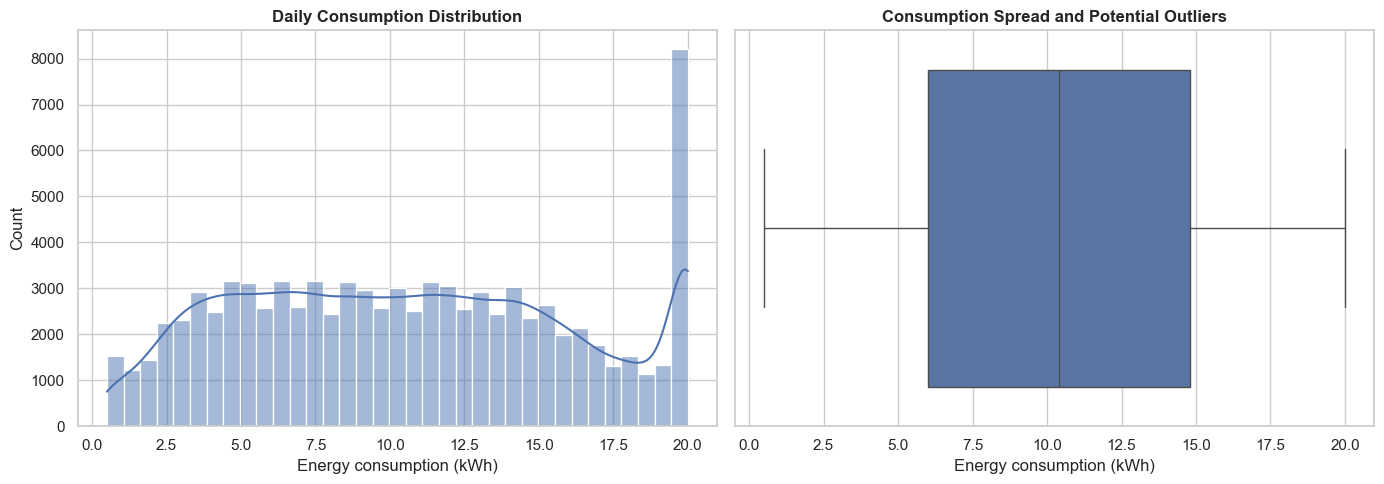

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(energy, bins=35, kde=True, ax=axes[0])
axes[0].set(title="Daily Consumption Distribution", xlabel="Energy consumption (kWh)")
sns.boxplot(x=energy, ax=axes[1])
axes[1].set(title="Consumption Spread and Potential Outliers", xlabel="Energy consumption (kWh)")
plt.tight_layout()
plt.show()

In [8]:
household_summary = (
    df.groupby("Household_ID", dropna=False)
      .agg(
          Total_Consumption_kWh=("Energy_Consumption_kWh", "sum"),
          Average_Daily_kWh=("Energy_Consumption_kWh", "mean"),
          Median_Daily_kWh=("Energy_Consumption_kWh", "median"),
          Peak_Usage_kWh=("Peak_Hours_Usage_kWh", "sum"),
          Observation_Days=("Date", "count"),
          Household_Size=("Household_Size", "median"),
          Has_AC=("Has_AC", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown")
      )
      .sort_values("Total_Consumption_kWh", ascending=False)
)
display(household_summary.head(10).round(2))

,Total_Consumption_kWh,Average_Daily_kWh,Median_Daily_kWh,Peak_Usage_kWh,Observation_Days,Household_Size,Has_AC
Household_ID,,,,,,,
H00017,140.0,20.0,20.0,61.1,7,6.0,Yes
H12807,140.0,20.0,20.0,61.5,7,6.0,Yes
H12829,140.0,20.0,20.0,62.5,7,6.0,Yes
H12763,140.0,20.0,20.0,63.7,7,6.0,Yes
H09311,140.0,20.0,20.0,63.6,7,6.0,Yes
H12776,140.0,20.0,20.0,63.0,7,6.0,Yes
H09212,140.0,20.0,20.0,65.0,7,6.0,Yes
H10747,140.0,20.0,20.0,62.5,7,6.0,Yes
H10757,140.0,20.0,20.0,62.1,7,6.0,Yes


,Household_Size,Average_Consumption_kWh,Median_Consumption_kWh,Average_Per_Person_kWh,Records
0,1,3.29,3.20,3.29,15260
1,2,6.23,6.20,3.11,15177
2,3,9.18,9.10,3.06,14651
3,4,12.25,12.20,3.06,14882
4,5,15.22,15.15,3.04,15372
5,6,17.47,18.50,2.91,14658


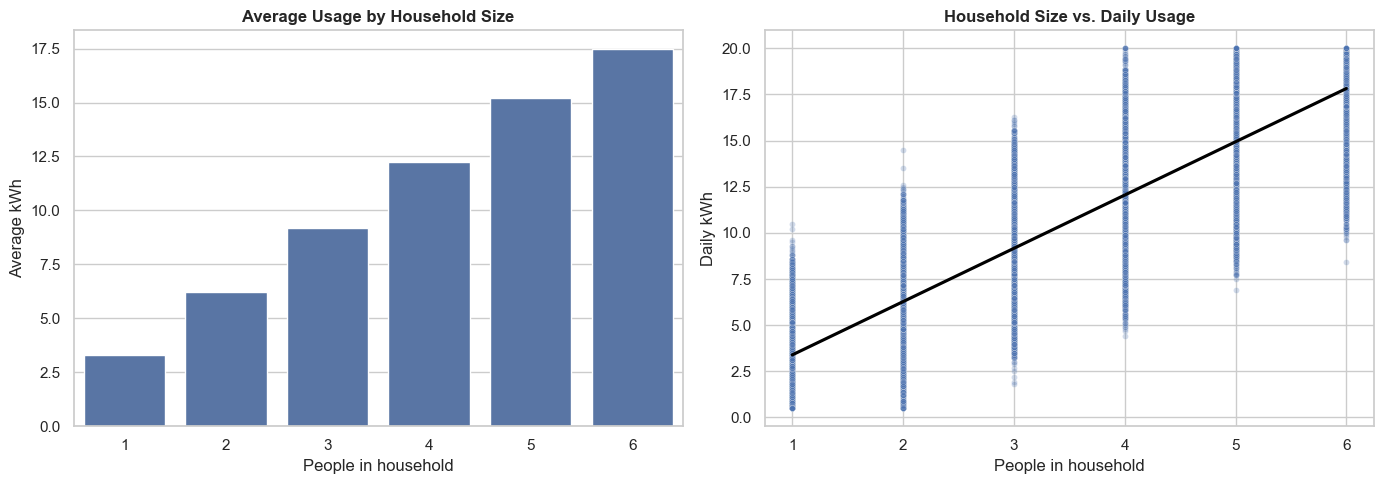

In [9]:
size_summary = (
    df.groupby("Household_Size", dropna=False)
      .agg(
          Average_Consumption_kWh=("Energy_Consumption_kWh", "mean"),
          Median_Consumption_kWh=("Energy_Consumption_kWh", "median"),
          Average_Per_Person_kWh=("Energy_per_Person_kWh", "mean"),
          Records=("Energy_Consumption_kWh", "size")
      ).reset_index().sort_values("Household_Size")
)
display(size_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=size_summary, x="Household_Size", y="Average_Consumption_kWh", ax=axes[0])
axes[0].set(title="Average Usage by Household Size", xlabel="People in household", ylabel="Average kWh")
sns.scatterplot(data=df, x="Household_Size", y="Energy_Consumption_kWh",
                alpha=0.25, s=18, ax=axes[1])
sns.regplot(data=df, x="Household_Size", y="Energy_Consumption_kWh",
            scatter=False, ci=None, ax=axes[1], color="black")
axes[1].set(title="Household Size vs. Daily Usage", xlabel="People in household", ylabel="Daily kWh")
plt.tight_layout()
plt.show()

,Has_AC,Average_Consumption_kWh,Median_Consumption_kWh,Average_Peak_Usage_kWh,Average_Peak_Usage_Pct,Households,Records
0,No,8.68,8.6,3.04,35.09,6501,45508
1,Yes,12.51,12.9,5.63,45.01,6356,44492


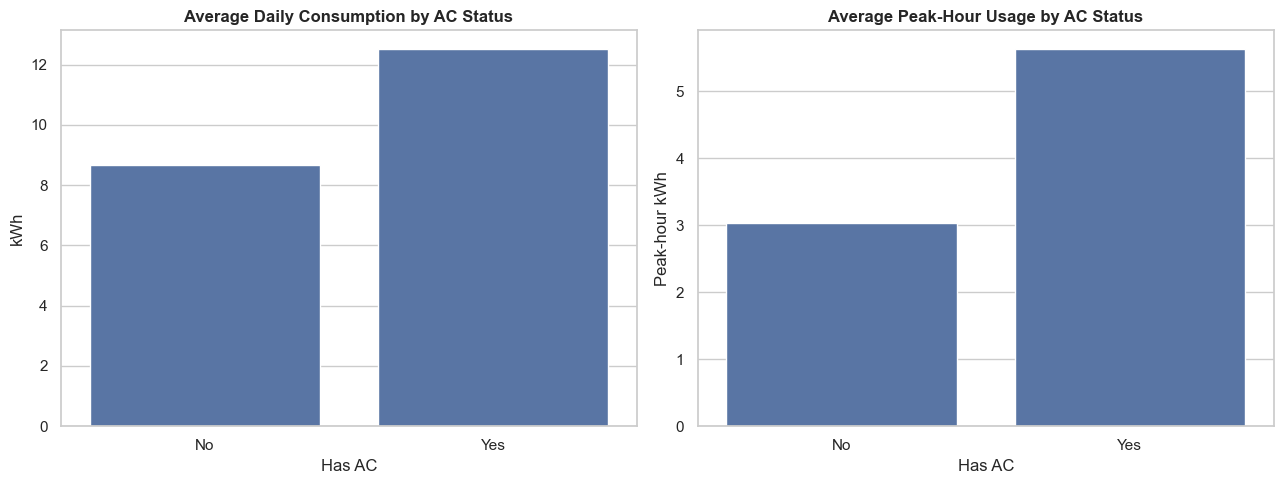

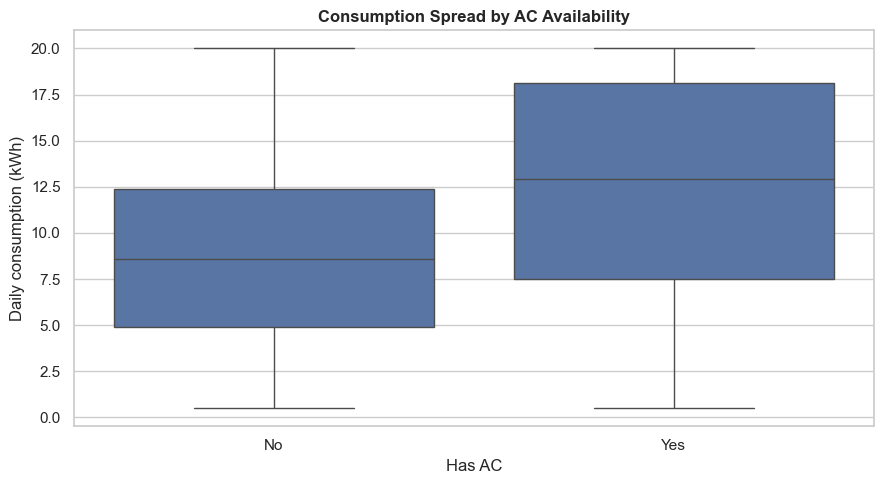

In [10]:
ac_summary = (
    df.groupby("Has_AC", dropna=False)
      .agg(
          Average_Consumption_kWh=("Energy_Consumption_kWh", "mean"),
          Median_Consumption_kWh=("Energy_Consumption_kWh", "median"),
          Average_Peak_Usage_kWh=("Peak_Hours_Usage_kWh", "mean"),
          Average_Peak_Usage_Pct=("Peak_Usage_Pct", "mean"),
          Households=("Household_ID", "nunique"),
          Records=("Household_ID", "size")
      ).reset_index()
)
display(ac_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=ac_summary, x="Has_AC", y="Average_Consumption_kWh", ax=axes[0])
axes[0].set(title="Average Daily Consumption by AC Status", xlabel="Has AC", ylabel="kWh")
sns.barplot(data=ac_summary, x="Has_AC", y="Average_Peak_Usage_kWh", ax=axes[1])
axes[1].set(title="Average Peak-Hour Usage by AC Status", xlabel="Has AC", ylabel="Peak-hour kWh")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Has_AC", y="Energy_Consumption_kWh")
plt.title("Consumption Spread by AC Availability")
plt.xlabel("Has AC"); plt.ylabel("Daily consumption (kWh)")
plt.tight_layout(); plt.show()

Pearson correlation between temperature and consumption: 0.033


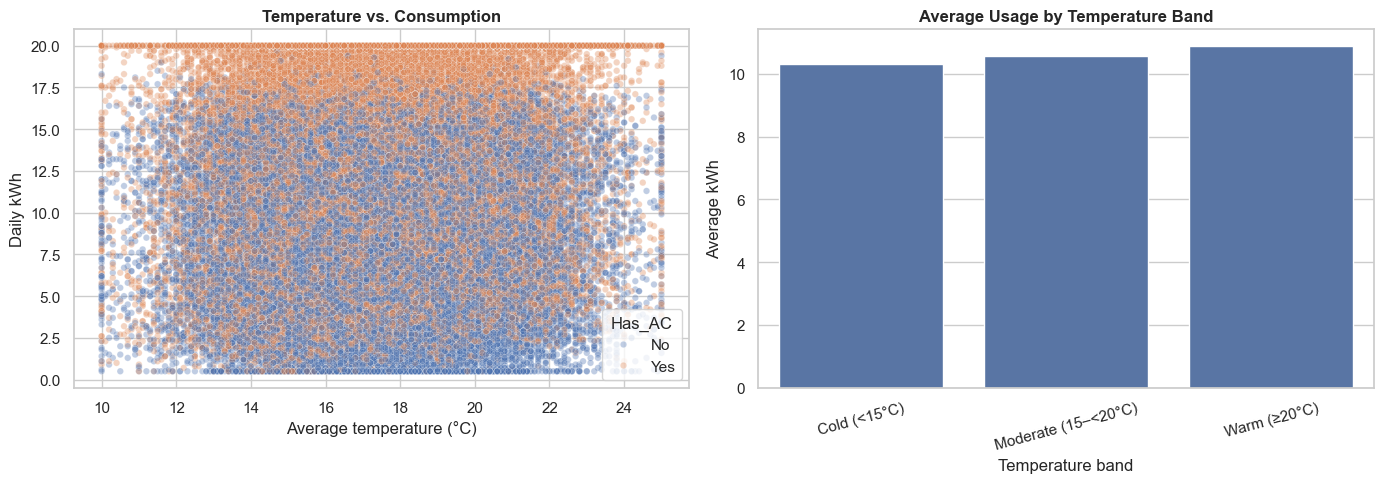

In [11]:
temp_corr = df[["Avg_Temperature_C", "Energy_Consumption_kWh"]].corr().iloc[0, 1]
print(f"Pearson correlation between temperature and consumption: {temp_corr:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="Avg_Temperature_C", y="Energy_Consumption_kWh",
                hue="Has_AC", alpha=0.35, s=22, ax=axes[0])
axes[0].set(title="Temperature vs. Consumption", xlabel="Average temperature (°C)", ylabel="Daily kWh")
temp_summary = df.groupby("Temperature_Category", observed=False)["Energy_Consumption_kWh"].mean().reset_index()
sns.barplot(data=temp_summary, x="Temperature_Category", y="Energy_Consumption_kWh", ax=axes[1])
axes[1].set(title="Average Usage by Temperature Band", xlabel="Temperature band", ylabel="Average kWh")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [17]:
daily = (
    df.groupby("Date")
      .agg(
          Total_Consumption_kWh=("Energy_Consumption_kWh", "sum"),
          Average_Consumption_kWh=("Energy_Consumption_kWh", "mean"),
          Households_Observed=("Household_ID", "nunique")
      ).reset_index().sort_values("Date")
)
display(daily.head())



,Date,Total_Consumption_kWh,Average_Consumption_kWh,Households_Observed
0,2025-04-01,135998.9,10.577810,12857
1,2025-04-02,135977.1,10.576114,12857
2,2025-04-03,135854.1,10.566547,12857
3,2025-04-04,136034.0,10.580540,12857
4,2025-04-05,135924.1,10.571992,12857


## Peak-hour usage

,count,mean,std,min,25%,50%,75%,max
Peak_Hours_Usage_kWh,90000.0,4.32,2.53,0.2,2.3,4.0,6.0,10.00
Peak_Usage_Pct,90000.0,39.99,5.79,25.0,35.0,40.0,45.0,55.56


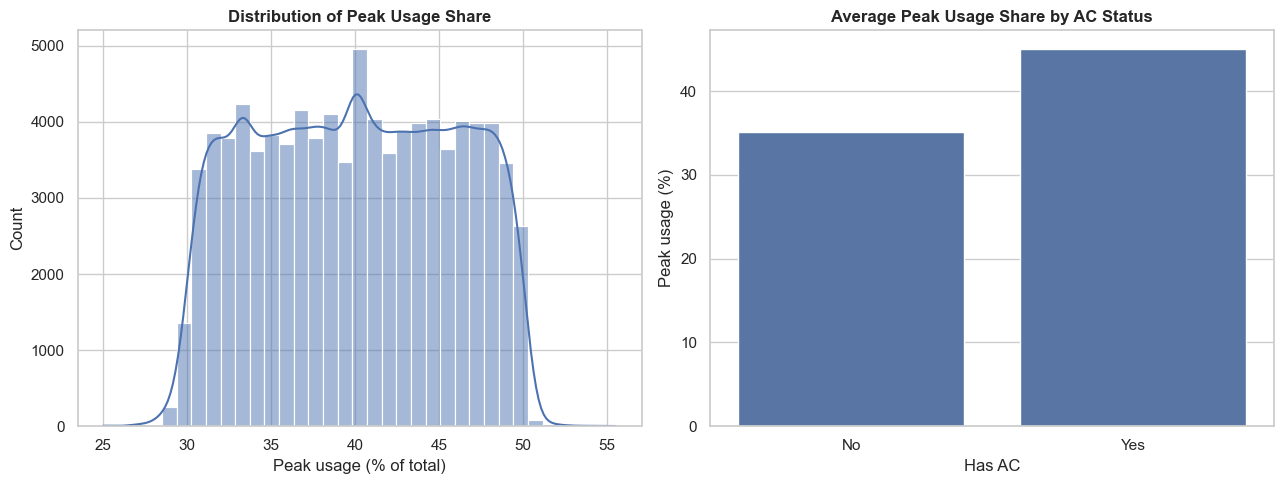

In [18]:
peak_summary = df[["Peak_Hours_Usage_kWh", "Peak_Usage_Pct"]].describe().T
display(peak_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["Peak_Usage_Pct"].dropna(), bins=35, kde=True, ax=axes[0])
axes[0].set(title="Distribution of Peak Usage Share", xlabel="Peak usage (% of total)")
peak_by_ac = df.groupby("Has_AC")["Peak_Usage_Pct"].mean().reset_index()
sns.barplot(data=peak_by_ac, x="Has_AC", y="Peak_Usage_Pct", ax=axes[1])
axes[1].set(title="Average Peak Usage Share by AC Status", xlabel="Has AC", ylabel="Peak usage (%)")
plt.tight_layout()
plt.show()

##  Outlier review

Use the IQR rule to flag unusually high consumption. A statistical flag is not a verdict: check source records and context before removing anything.

In [21]:
q1 = df["Energy_Consumption_kWh"].quantile(0.25)
q3 = df["Energy_Consumption_kWh"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
df["High_Consumption_Flag"] = df["Energy_Consumption_kWh"] > upper_fence

outliers = df.loc[df["High_Consumption_Flag"],
                  ["Household_ID", "Date", "Energy_Consumption_kWh",
                   "Household_Size", "Avg_Temperature_C", "Has_AC",
                   "Peak_Hours_Usage_kWh"]].sort_values("Energy_Consumption_kWh", ascending=False)
print(f"IQR upper fence: {upper_fence:.2f} kWh")
print(f"Flagged records: {len(outliers):,} ({len(outliers)/len(df):.2%} of all rows)")
display(outliers.head(20))

IQR upper fence: 28.00 kWh
Flagged records: 0 (0.00% of all rows)


,Household_ID,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh


## Summary

In [20]:
overall_mean = df["Energy_Consumption_kWh"].mean()
overall_median = df["Energy_Consumption_kWh"].median()
top_household = household_summary.index[0] if len(household_summary) else "N/A"
top_total = household_summary.iloc[0]["Total_Consumption_kWh"] if len(household_summary) else np.nan
size_corr = df[["Household_Size", "Energy_Consumption_kWh"]].corr().iloc[0,1]
ac_means = df.groupby("Has_AC")["Energy_Consumption_kWh"].mean()
ac_line = "AC groups could not be compared." if len(ac_means) < 2 else (
    f"Average usage was {ac_means.get('Yes', np.nan):.2f} kWh for AC households "
    f"and {ac_means.get('No', np.nan):.2f} kWh for non-AC households."
)
display(Markdown(f'''
- **Average daily record:** {overall_mean:.2f} kWh; **median:** {overall_median:.2f} kWh.
- **Highest total-consuming household:** {top_household} ({top_total:,.1f} kWh over observed records).
- **Household size association:** Pearson r = {size_corr:.3f}.
- **Temperature association:** Pearson r = {temp_corr:.3f}.
- **AC comparison:** {ac_line}
- **Potential high-consumption records:** {int(df["High_Consumption_Flag"].sum()):,} flagged by the IQR rule.
'''))


- **Average daily record:** 10.57 kWh; **median:** 10.40 kWh.
- **Highest total-consuming household:** H00017 (140.0 kWh over observed records).
- **Household size association:** Pearson r = 0.894.
- **Temperature association:** Pearson r = 0.033.
- **AC comparison:** Average usage was 12.51 kWh for AC households and 8.68 kWh for non-AC households.
- **Potential high-consumption records:** 0 flagged by the IQR rule.


## Export reusable summary tables

In [16]:
OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
household_summary.to_csv(OUTPUT_DIR / "household_summary.csv")
daily.to_csv(OUTPUT_DIR / "daily_consumption.csv", index=False)
quality.to_csv(OUTPUT_DIR / "data_quality_summary.csv")
outliers.to_csv(OUTPUT_DIR / "high_consumption_flags.csv", index=False)
print(f"Summary files saved to: {OUTPUT_DIR.resolve()}")

Summary files saved to: C:\Users\hasya\OneDrive\Desktop\House Hold Energy Consuption\eda_outputs
